# Prerequisite learning

**Phase 1 · TP-02**

Run these cells in order using **Python 3.13 (RPS CNN)**. The examples use small arrays and an in-memory color swatch. You can optionally inspect a personal image you have permission to use. These inputs are only for learning.

By the end, you should be able to trace an image from pixels to a batch and explain what a forward pass and its loss mean.

## 1. Arrays, indexing, and shapes

An array's shape gives the length of each axis. Image arrays often use height, width, and channel order. NumPy uses zero-based indexing. A colon selects the entire axis.

In [1]:
%matplotlib inline

import io
import sys

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from PIL import Image, ImageOps

print("Python:", sys.version.split()[0])
print("Kernel interpreter:", sys.executable)
assert sys.version_info[:2] == (3, 13)

swatch = np.array([
    [[255, 0, 0], [0, 255, 0], [0, 0, 255]],
    [[255, 255, 255], [128, 128, 128], [0, 0, 0]],
], dtype=np.uint8)

print("Shape:", swatch.shape, "rank:", swatch.ndim)
print("Top-left pixel:", swatch[0, 0])
print("Green channel:")
print(swatch[:, :, 1])

Python: 3.13.3
Kernel interpreter: c:\Users\Niyati\OneDrive\Desktop\rock-paper-scissors-cnn\.venv313\Scripts\python.exe
Shape: (2, 3, 3) rank: 3
Top-left pixel: [255   0   0]
Green channel:
[[  0 255   0]
 [255 128   0]]


**Try it.** Predict the values at row 1, column 1. Slice out just the blue channel and explain why it has shape `(2, 3)`.

## 2. Decode and visualize an image

A PNG or JPEG stores encoded bytes. A decoder produces a pixel grid. An RGB pixel has three values representing red, green, and blue. The default example loads a PNG of the swatch from memory. To examine a separate personal image, set `example_path` to its path. The cell adjusts EXIF orientation, then converts the image to RGB.

Decoded shape: (2, 3, 3) dtype: uint8


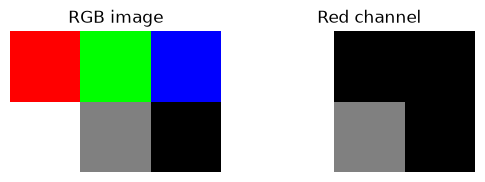

In [2]:
example_path = ""
if example_path:
    source = example_path
else:
    source = io.BytesIO()
    Image.fromarray(swatch).save(source, format="PNG")
    source.seek(0)

with Image.open(source) as image:
    pixels = np.asarray(ImageOps.exif_transpose(image).convert("RGB"))

print("Decoded shape:", pixels.shape, "dtype:", pixels.dtype)

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(pixels)
axes[0].set_title("RGB image")
axes[1].imshow(pixels[:, :, 0], cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Red channel")
for axis in axes:
    axis.axis("off")
plt.show()

**Try it.** Display the green channel. With the default swatch, explain why the pure green pixel appears bright in that view.

## 3. Normalize, create a tensor, and add the batch axis

Cast unsigned 8-bit pixel values to float32 and divide by 255. This maps the full 0–255 range to 0–1. A TensorFlow model typically processes a batch of images with shape `[B, H, W, C]`, where `B` counts images. One image still needs a batch axis.

In [3]:
normalized = pixels.astype(np.float32) / 255.0
tensor = tf.convert_to_tensor(normalized, dtype=tf.float32)
one_image_batch = tf.expand_dims(tensor, axis=0)
two_image_batch = tf.stack([tensor, tensor], axis=0)

print("Normalized range:", float(tf.reduce_min(tensor)), float(tf.reduce_max(tensor)))
print("Single image:", tensor.shape)
print("One-image batch:", one_image_batch.shape)
print("Two-image batch:", two_image_batch.shape)
print("Mean per RGB channel:", tf.reduce_mean(tensor, axis=(0, 1)).numpy())

assert tensor.dtype == tf.float32
assert one_image_batch.shape[0] == 1
np.testing.assert_array_equal(one_image_batch[0], tensor)

Normalized range: 0.0 1.0
Single image: (2, 3, 3)
One-image batch: (1, 2, 3, 3)
Two-image batch: (2, 2, 3, 3)
Mean per RGB channel: [0.41699347 0.41699347 0.41699347]


**Try it.** Predict the result of normalizing the value 128. Explain how adding a batch axis differs from adding a color channel.

## 4. Forward pass and loss

A dense layer multiplies the feature row by weights and adds a bias, `logits = features @ weights + bias`. A convolutional layer instead applies shared filters across spatial neighborhoods. Both use learned weights in a trained network. Here the weights are fixed so the arithmetic can be checked by hand.

Softmax converts the two logits into scores that sum to one. Sparse cross-entropy uses the integer index of the true class and penalizes a low score for it. The loss function below takes logits and internally handles the softmax calculation.

In [4]:
features = tf.constant([[1.0, 2.0]], dtype=tf.float32)  # [batch, features]
weights = tf.constant([[0.25, 0.5], [-0.5, 0.25]], dtype=tf.float32)
bias = tf.constant([0.25, -0.25], dtype=tf.float32)

logits = tf.matmul(features, weights) + bias
scores = tf.nn.softmax(logits, axis=-1)

label = tf.constant([1], dtype=tf.int32)  # second class, one label per row
loss = tf.nn.sparse_softmax_cross_entropy_with_logits(labels=label, logits=logits)
manual_loss = -tf.math.log(scores[0, 1])
np.testing.assert_allclose(loss[0], manual_loss, rtol=0, atol=1e-6)

print("Logits:", logits.numpy(), "shape:", logits.shape)
print("Scores:", scores.numpy())
print("Loss:", float(loss[0]))

Logits: [[-0.5   0.75]] shape: (1, 2)
Scores: [[0.22270013 0.7772999 ]]
Loss: 0.25192904472351074


## Self-directed reflection

1. What do the axes mean in `[1, 2, 3, 3]` for the default swatch? How do you select the green channel of the unbatched image?
2. What value does 128 map to? What would dividing by 255 twice do to the darkest and brightest values?
3. Calculate the two logits from the fixed weights. Which class has the higher score? Predict what will happen to the loss if the label changes from 1 to 0, then verify it.
4. Why does a CNN preserve the height and width axes when it receives an image?

Use these questions to check your understanding at your own pace. TP-02 verifies that the notebook’s code cells run and produce the expected outputs.